# 1. Contexte métier et problématique

## 1.1 Contexte

TouNum est une entreprise spécialisée dans la numérisation de documents, notamment à partir de supports papier. Dans le cadre de l'augmentation du volume de documents numérisés, l'entreprise souhaite développer de nouveaux services reposant sur les techniques de Machine Learning.

L'un des objectifs du projet consiste à mettre en place une chaîne automatisée permettant d'analyser des images et, à terme, de générer automatiquement une légende descriptive de leur contenu.

Avant de réaliser cette étape de génération de légendes (*image captioning*), une étape de filtrage est nécessaire. En effet, l'ensemble des images numérisées par TouNum ne correspond pas nécessairement à des photographies. Le dataset peut également contenir des schémas, des graphiques, des textes scannés, des dessins ou encore des peintures.

L'objectif de ce premier livrable est donc de développer un modèle de classification capable de distinguer automatiquement :

* les **photographies** ;
* les **autres types d'images**.

Cette classification permettra de sélectionner automatiquement les photographies qui pourront ensuite être transmises aux étapes suivantes du workflow.

## 1.2 Problématique

La problématique étudiée dans ce livrable est donc la suivante :

**Comment développer un modèle de réseau de neurones capable de distinguer automatiquement une photographie d'une autre catégorie d'image dans un ensemble de documents numérisés ?**

La difficulté du problème dépend notamment de la nature des images à distinguer. Les textes scannés ou les schémas présentent généralement des caractéristiques visuelles très différentes des photographies. À l'inverse, certaines peintures possèdent un rendu très réaliste et peuvent donc être visuellement proches d'une photographie.

L'objectif sera ainsi de construire progressivement un modèle, d'évaluer ses performances et d'analyser ses limites afin de déterminer s'il est suffisamment pertinent pour être intégré au workflow de TouNum.


# 2. Objectif de la classification

Le problème est formulé comme une **classification binaire supervisée**.

Deux classes sont retenues :

| Classe | Signification | Exemples                                          |
| ------ | ------------- | ------------------------------------------------- |
| `0`    | Autre         | Schéma, graphique, texte scanné, dessin, peinture |
| `1`    | Photo         | Photographie                                      |

Les datasets fournis par TouNum sont initialement répartis dans différents répertoires selon leur nature. L'absence d'étiquette explicite dans les fichiers ne constitue donc pas un problème : la classe pourra être automatiquement déterminée à partir du répertoire dans lequel se trouve chaque image.

L'objectif final est d'obtenir un modèle capable de prendre une image en entrée et de produire une prédiction binaire :

**Image → Réseau de neurones → Photo / Autre**

Cette première classification constitue une étape de filtrage. Les images identifiées comme des photographies pourront ensuite être transmises aux étapes de traitement d'image et de génération automatique de légendes.


## 3. Importation des librairies

In [1]:
import os
import pathlib
import numpy as np
import matplotlib.pyplot as plt
import pathlib

In [2]:
os.environ['KERAS_BACKEND'] = 'torch'
import keras
from keras import layers
import tensorflow as tf

I0000 00:00:1791148422.023684   71828 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791148422.674219   71828 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791148424.430190   71828 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791148424.433411   71828 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will 

In [3]:
#pour pouvoir entraîner avec le gpu
print("Active backend:", keras.backend.backend())

Active backend: torch


In [4]:
import torch.cuda as cuda

print(cuda.is_available())
if cuda.is_available():
    print(cuda.get_device_name(0))

True
NVIDIA GeForce RTX 5070 Laptop GPU


## 4. Exploration et visualisation des données du dataset

Commençons tout d'abord par explorer les classes du dataset.


In [5]:
datasets_dir = pathlib.Path('datasets') #D:/datasets

In [6]:
invalid_files = []

for file_path in datasets_dir.rglob("*"):
    if file_path.is_file():
        try:
            content = tf.io.read_file(str(file_path))
            _ = tf.io.decode_image(content, expand_animations=False)
        except tf.errors.InvalidArgumentError as e:
            print(f"Fichier corrompu trouvé : {file_path}")
            print(f"Erreur : {e}\n")
            invalid_files.append((file_path, e))

print(f"{len(invalid_files)} fichier(s) invalide(s)")

for file_path, error in invalid_files:
    print(file_path, "->", error)

W0000 00:00:1791148425.548352   71828 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Fichier corrompu trouvé : datasets/Schematics/desktop.ini
Erreur : {{function_node __wrapped__DecodeImage_device_/job:localhost/replica:0/task:0/device:CPU:0}} Unknown image file format. One of JPEG, JPEG XL, PNG, GIF, BMP, WebP required. [Op:DecodeImage] name: 



W0000 00:00:1791148438.850765   71828 local_rendezvous.cc:412] Local rendezvous is aborting with status: INVALID_ARGUMENT: Unknown image file format. One of JPEG, JPEG XL, PNG, GIF, BMP, WebP required.
Corrupt JPEG data: 419 extraneous bytes before marker 0xd9
W0000 00:00:1791148496.138889   71828 local_rendezvous.cc:412] Local rendezvous is aborting with status: INVALID_ARGUMENT: Input size should match (header_size + row_size * abs_height) but they differ by 2


Fichier corrompu trouvé : datasets/Painting/painting_02662.jpg
Erreur : {{function_node __wrapped__DecodeImage_device_/job:localhost/replica:0/task:0/device:CPU:0}} Input size should match (header_size + row_size * abs_height) but they differ by 2 [Op:DecodeImage] name: 



W0000 00:00:1791148501.343542   71828 png_io.cc:96] PNG warning: iCCP: known incorrect sRGB profile


2 fichier(s) invalide(s)
datasets/Schematics/desktop.ini -> {{function_node __wrapped__DecodeImage_device_/job:localhost/replica:0/task:0/device:CPU:0}} Unknown image file format. One of JPEG, JPEG XL, PNG, GIF, BMP, WebP required. [Op:DecodeImage] name: 
datasets/Painting/painting_02662.jpg -> {{function_node __wrapped__DecodeImage_device_/job:localhost/replica:0/task:0/device:CPU:0}} Input size should match (header_size + row_size * abs_height) but they differ by 2 [Op:DecodeImage] name: 


In [7]:
for invalid_file in invalid_files:
    invalid_file[0].unlink()

In [8]:
batch_size, img_height, img_width, epochs = 32, 128, 128, 10

In [9]:
def build_datasets(data_dir, batch_size, img_size):
    seed_value = 42

    train_ds = keras.utils.image_dataset_from_directory(
        directory=data_dir,
        validation_split=0.3,
        subset="training",
        seed=seed_value,
        image_size=img_size,
        batch_size=batch_size,
    )

    val_and_test_ds = keras.utils.image_dataset_from_directory(
        directory=data_dir,
        validation_split=0.3,
        subset="validation",
        seed=seed_value,
        image_size=img_size,
        batch_size=batch_size,
    )

    num_eval_batches = tf.data.experimental.cardinality(val_and_test_ds).numpy()
    val_batches = num_eval_batches // 2

    val_ds = val_and_test_ds.take(val_batches)
    test_ds = val_and_test_ds.skip(val_batches)

    return train_ds, val_ds, test_ds

train_ds, val_ds, test_ds = build_datasets(datasets_dir, batch_size=batch_size, img_size=(img_height, img_width))

Found 34096 files belonging to 5 classes.
Using 23868 files for training.
Found 34096 files belonging to 5 classes.
Using 10228 files for validation.


In [10]:
labels = train_ds.class_names

class_distribution = {
    label: sum(1 for file in (datasets_dir / label).iterdir() if file.is_file())
    for label in labels
}

print(class_distribution)

{'Painting': 8172, 'Photo': 8173, 'Schematics': 8172, 'Sketch': 1406, 'Text': 8173}


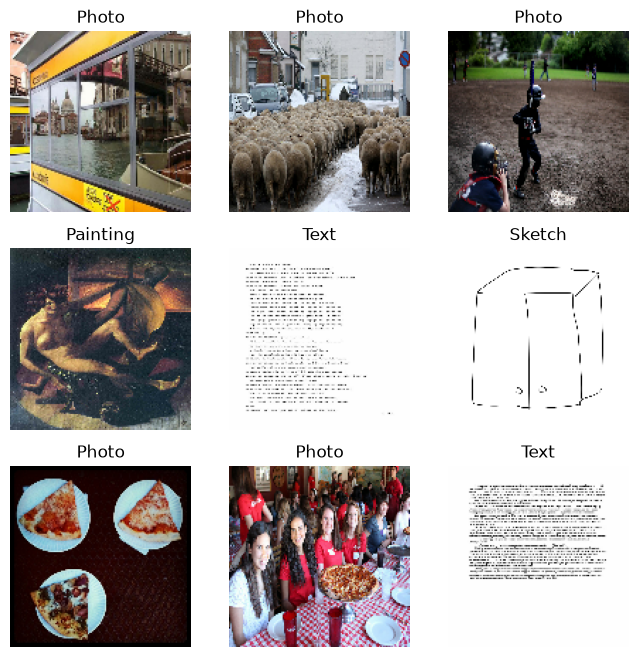

In [11]:
plt.figure(figsize=(8, 8))
for images, label in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i +1)
        ax.imshow(images[i].numpy().astype('uint8'))
        plt.title(labels[label[i]])
        plt.axis("off")

## Chargement des données dans le cache pour optimiser l'entraînement

In [12]:
def cast_to_uint8(images, labels):
    images = tf.cast(images, tf.uint8)
    return images, labels

In [13]:
AUTOTUNE = tf.data.experimental.AUTOTUNE

train_data = train_ds.map(cast_to_uint8, num_parallel_calls=tf.data.AUTOTUNE).cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_data = val_ds.map(cast_to_uint8, num_parallel_calls=tf.data.AUTOTUNE).cache().prefetch(buffer_size=AUTOTUNE)
test_data = test_ds.map(cast_to_uint8, num_parallel_calls=tf.data.AUTOTUNE).cache().prefetch(buffer_size=AUTOTUNE)

In [14]:
import psutil
from tqdm import tqdm

process = psutil.Process(os.getpid())

def preload_and_cache(dataset, total_batches, split_name="Dataset"):
    initial_ram = process.memory_info().rss / (1024 ** 2)
    print(f"\n--- Caching {split_name} (RAM before: {initial_ram:.1f} MB) ---")
    
    for _ in tqdm(dataset, total=total_batches, desc=f"Loading {split_name}", unit="batch"):
        pass

    final_ram = process.memory_info().rss / (1024 ** 2)
    delta_ram = final_ram - initial_ram
    print(f"{split_name} cached. RAM used: {final_ram:.1f} MB (+{delta_ram:.1f} MB added)")

preload_and_cache(train_data, len(train_ds), "Train")
preload_and_cache(val_data, len(val_ds), "Validation")
preload_and_cache(test_data, len(test_ds), "Test")


--- Caching Train (RAM before: 1722.2 MB) ---


Loading Train:   0%|          | 0/746 [00:00<?, ?batch/s]Corrupt JPEG data: 419 extraneous bytes before marker 0xd9
W0000 00:00:1791148537.879389   72533 png_io.cc:96] PNG warning: iCCP: known incorrect sRGB profile
Loading Train: 100%|██████████| 746/746 [00:06<00:00, 108.89batch/s]


Train cached. RAM used: 3769.4 MB (+2047.2 MB added)

--- Caching Validation (RAM before: 3769.4 MB) ---


Loading Validation: 100%|██████████| 160/160 [00:02<00:00, 71.02batch/s]


Validation cached. RAM used: 4554.3 MB (+784.9 MB added)

--- Caching Test (RAM before: 4554.3 MB) ---


Loading Test: 100%|██████████| 160/160 [00:04<00:00, 36.38batch/s]

Test cached. RAM used: 4954.2 MB (+399.8 MB added)


## Construction du modèle CNN

Un réseau de neurones convolutif (CNN) est utilisé car il est particulièrement adapté à l'analyse d'images.

Les couches de convolution permettent d'extraire progressivement des caractéristiques visuelles :
- contours ;
- textures ;
- formes ;
- motifs plus complexes.

Les couches de MaxPooling réduisent progressivement la résolution spatiale des représentations tout en conservant les informations les plus importantes.

Une couche Flatten transforme ensuite la représentation multidimensionnelle en vecteur afin de pouvoir utiliser des couches denses pour la classification.

La dernière couche contient un seul neurone associé à une fonction d'activation sigmoïde. Elle produit une probabilité comprise entre 0 et 1 correspondant à la probabilité que l'image appartienne à la classe « Photo ».

In [15]:
model_baseline = keras.Sequential([

    layers.Input(shape=(img_height, img_width, 3)),
    layers.Rescaling(1./255),
    layers.Conv2D(32, (3, 3),activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64,(3, 3),activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128,(3, 3),activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(len(labels), activation="softmax")
])

model_baseline.summary()

model_baseline.compile(optimizer="adam", loss ='sparse_categorical_crossentropy', metrics=['accuracy'])

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,285 (12.61 MB)

 Trainable params: 3,305,285 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:
history_baseline = model_baseline.fit(
    train_data,
    validation_data=val_data,
    epochs=epochs,
    batch_size=batch_size,
)

Epoch 1/10


/home/jxc/school/cesi/Leyenda/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


746/746 ━━━━━━━━━━━━━━━━━━━━ 25s 19ms/step - accuracy: 0.7491 - loss: 0.5851 - val_accuracy: 0.8174 - val_loss: 0.4313
Epoch 2/10
746/746 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - accuracy: 0.8520 - loss: 0.3594 - val_accuracy: 0.8729 - val_loss: 0.3149
Epoch 3/10
746/746 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - accuracy: 0.8849 - loss: 0.2865 - val_accuracy: 0.8844 - val_loss: 0.3004
Epoch 4/10
746/746 ━━━━━━━━━━━━━━━━━━━━ 14s 19ms/step - accuracy: 0.9088 - loss: 0.2309 - val_accuracy: 0.8881 - val_loss: 0.2952
Epoch 5/10
746/746 ━━━━━━━━━━━━━━━━━━━━ 12s 17ms/step - accuracy: 0.9313 - loss: 0.1747 - val_accuracy: 0.8889 - val_loss: 0.3143
Epoch 6/10
746/746 ━━━━━━━━━━━━━━━━━━━━ 14s 19ms/step - accuracy: 0.9479 - loss: 0.1394 - val_accuracy: 0.8979 - val_loss: 0.3149
Epoch 7/10
746/746 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - accuracy: 0.9640 - loss: 0.0980 - val_accuracy: 0.8912 - val_loss: 0.3849
Epoch 8/10
746/746 ━━━━━━━━━━━━━━━━━━━━ 22s 29ms/step - accuracy: 0.9759 - loss: 0.0684 - val_accurac

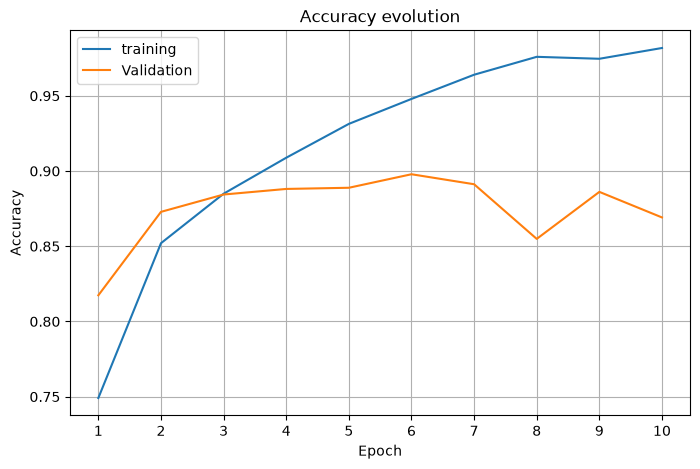

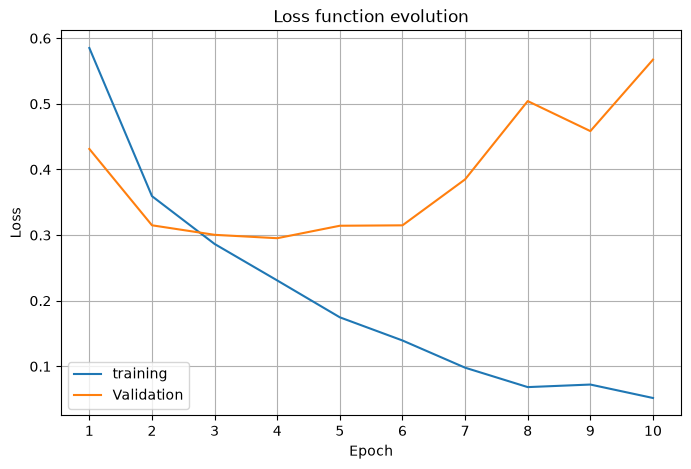

In [17]:
acc = history_baseline.history["accuracy"]
val_acc = history_baseline.history["val_accuracy"]
loss = history_baseline.history["loss"]
val_loss = history_baseline.history["val_loss"]
actual_epochs = range(1, epochs + 1)

# accuracy plots
plt.figure(figsize=(8, 5))
plt.plot(actual_epochs, acc, label="training")
plt.plot(actual_epochs, val_acc, label="Validation")
plt.title("Accuracy evolution")
plt.xticks(actual_epochs)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# loss plots
plt.figure(figsize=(8, 5))
plt.plot(actual_epochs, loss, label="training")
plt.plot(actual_epochs, val_loss, label="Validation")
plt.title("Loss function evolution")
plt.xticks(actual_epochs)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [18]:
print(f'final training loss: {loss[-1]}\nfinal validation loss: {val_loss[-1]}')
print(f'--- generalization gap: {abs(loss[-1] - val_loss[-1])} ---')
print(f'\nfinal training accuracy: {acc[-1]}\nfinal validation accuracy: {val_acc[-1]}')
print(f'--- accuracy gap: {abs(acc[-1] - val_acc[-1])} ---')

final training loss: 0.05177917703986168
final validation loss: 0.5673641562461853
--- generalization gap: 0.5155849792063236 ---

final training accuracy: 0.9817747473716736
final validation accuracy: 0.869140625
--- accuracy gap: 0.11263412237167358 ---


In [19]:
model_baseline.save('model_baseline.weights.h5')

On peut voir que le modèle est en surapprentissage, nous allons tester différentes techniques pour réduire l'erreur de généralisation

## Data augmentation sur la classe Sketch

La classe `Sketch` est largement minoritaire dans le dataset (environ 1 400 images contre plus de 8 000 pour les autres classes). Le modèle baseline voit donc très peu de croquis pendant l'entraînement : il a tendance à les confondre avec d'autres classes et à mémoriser les quelques exemples disponibles.

Pour compenser ce déséquilibre, nous appliquons une **data augmentation ciblée** : uniquement les images `Sketch` du jeu d'entraînement sont dupliquées puis transformées aléatoirement (retournement, rotation, zoom, translation, contraste). Les autres classes restent inchangées, tout comme les jeux de validation et de test, afin que l'évaluation reste comparable à celle du baseline.

L'architecture du modèle est strictement identique à celle du baseline : seule la composition du jeu d'entraînement change.

classe       precision    recall        f1   support
Painting         0.816     0.740     0.776      1206
Photo            0.815     0.817     0.816      1197
Schematics       0.880     0.940     0.909      1258
Sketch           0.907     0.985     0.945       199
Text             0.993     0.998     0.996      1248

accuracy globale : 0.8800


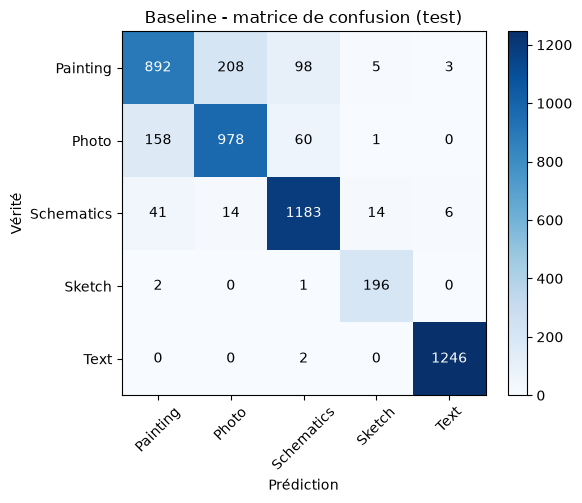

In [20]:
def per_class_metrics(model, dataset):
    y_true, y_pred = [], []
    for images, batch_labels in dataset:
        probs = model.predict_on_batch(images)
        y_true.append(np.asarray(batch_labels))
        y_pred.append(np.argmax(np.asarray(probs), axis=1))
    y_true, y_pred = np.concatenate(y_true), np.concatenate(y_pred)

    confusion = np.zeros((len(labels), len(labels)), dtype=int)
    for t, p in zip(y_true, y_pred):
        confusion[t, p] += 1

    print(f"{'classe':<12}{'precision':>10}{'recall':>10}{'f1':>10}{'support':>10}")
    for i, label in enumerate(labels):
        tp = confusion[i, i]
        precision = tp / max(confusion[:, i].sum(), 1)
        recall = tp / max(confusion[i, :].sum(), 1)
        f1 = 2 * precision * recall / max(precision + recall, 1e-9)
        print(f"{label:<12}{precision:>10.3f}{recall:>10.3f}{f1:>10.3f}{confusion[i, :].sum():>10}")
    print(f"\naccuracy globale : {np.trace(confusion) / confusion.sum():.4f}")

    return confusion

def plot_confusion(confusion, title):
    plt.figure(figsize=(6, 5))
    plt.imshow(confusion, cmap="Blues")
    plt.title(title)
    plt.xticks(range(len(labels)), labels, rotation=45)
    plt.yticks(range(len(labels)), labels)
    plt.xlabel("Prédiction")
    plt.ylabel("Vérité")
    for i in range(len(labels)):
        for j in range(len(labels)):
            plt.text(j, i, confusion[i, j], ha="center", va="center",
                     color="white" if confusion[i, j] > confusion.max() / 2 else "black")
    plt.colorbar()
    plt.tight_layout()
    plt.show()

confusion_baseline = per_class_metrics(model_baseline, test_data)
plot_confusion(confusion_baseline, "Baseline - matrice de confusion (test)")

In [21]:
sketch_index = labels.index("Sketch")

# fond blanc pour les zones créées par rotation / zoom / translation (les croquis sont sur fond clair)
sketch_augmentation = [
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05, fill_mode="constant", fill_value=255.0),
    layers.RandomZoom(0.1, fill_mode="constant", fill_value=255.0),
    layers.RandomTranslation(0.1, 0.1, fill_mode="constant", fill_value=255.0),
    layers.RandomContrast(0.2, value_range=(0, 255)),
]

# les couches sont appelées une par une : un keras.Sequential ne peut pas être utilisé dans tf.data avec le backend torch
def augment_sketch(image, label):
    image = tf.cast(image, tf.float32)
    for layer in sketch_augmentation:
        image = layer(image, training=True)
    return image, label

def to_float32(image, label):
    return tf.cast(image, tf.float32), label

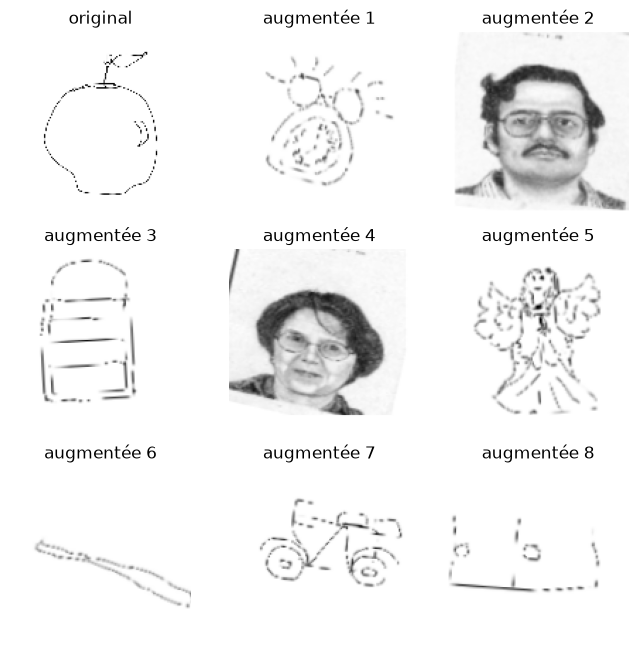

In [22]:
sketch_sample = train_data.unbatch().filter(lambda image, label: tf.equal(label, sketch_index)).take(1)
augmented_samples = sketch_sample.repeat(8).map(augment_sketch)

plt.figure(figsize=(8, 8))
for i, (image, _) in enumerate(sketch_sample.concatenate(augmented_samples.map(lambda image, label: (tf.cast(image, tf.uint8), label)))):
    ax = plt.subplot(3, 3, i + 1)
    ax.imshow(image.numpy())
    plt.title("original" if i == 0 else f"augmentée {i}")
    plt.axis("off")

In [23]:
train_label_counts = np.bincount(
    np.concatenate([np.asarray(batch_labels) for _, batch_labels in train_data]),
    minlength=len(labels),
)
print(dict(zip(labels, train_label_counts)))

n_sketch = train_label_counts[sketch_index]
n_others = train_label_counts.sum() - n_sketch
mean_other_class = n_others / (len(labels) - 1)

# nombre de copies augmentées par croquis pour atteindre la taille moyenne des autres classes
augmentation_factor = max(int(round(mean_other_class / n_sketch)) - 1, 1)
n_sketch_total = n_sketch * (1 + augmentation_factor)
print(f"facteur d'augmentation : {augmentation_factor} -> {n_sketch_total} images Sketch par epoch")

train_unbatched = train_data.unbatch()

sketch_original = train_unbatched.filter(lambda image, label: tf.equal(label, sketch_index)).map(to_float32)
sketch_augmented = (
    train_unbatched.filter(lambda image, label: tf.equal(label, sketch_index))
    .repeat(augmentation_factor)
    .map(augment_sketch, num_parallel_calls=AUTOTUNE)
)
sketch_ds = sketch_original.concatenate(sketch_augmented).shuffle(2000)
others_ds = train_unbatched.filter(lambda image, label: tf.not_equal(label, sketch_index)).map(to_float32)

train_data_aug = (
    tf.data.Dataset.sample_from_datasets(
        [others_ds, sketch_ds],
        weights=[n_others / (n_others + n_sketch_total), n_sketch_total / (n_others + n_sketch_total)],
    )
    .batch(batch_size)
    .prefetch(buffer_size=AUTOTUNE)
)

{'Painting': np.int64(5714), 'Photo': np.int64(5732), 'Schematics': np.int64(5695), 'Sketch': np.int64(1003), 'Text': np.int64(5724)}
facteur d'augmentation : 5 -> 6018 images Sketch par epoch


In [24]:
model_sketch_aug = keras.models.clone_model(model_baseline)  # même architecture, poids réinitialisés

model_sketch_aug.compile(optimizer="adam", loss='sparse_categorical_crossentropy', metrics=['accuracy'])

history_sketch_aug = model_sketch_aug.fit(
    train_data_aug,
    validation_data=val_data,
    epochs=epochs,
)

/home/jxc/school/cesi/Leyenda/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/10
    901/Unknown 23s 20ms/step - accuracy: 0.7810 - loss: 0.5258

/home/jxc/school/cesi/Leyenda/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


903/903 ━━━━━━━━━━━━━━━━━━━━ 24s 21ms/step - accuracy: 0.7814 - loss: 0.5249 - val_accuracy: 0.8027 - val_loss: 0.5114
Epoch 2/10
903/903 ━━━━━━━━━━━━━━━━━━━━ 24s 20ms/step - accuracy: 0.8710 - loss: 0.3207 - val_accuracy: 0.8527 - val_loss: 0.3870
Epoch 3/10
903/903 ━━━━━━━━━━━━━━━━━━━━ 26s 22ms/step - accuracy: 0.8991 - loss: 0.2560 - val_accuracy: 0.7824 - val_loss: 0.5894
Epoch 4/10
903/903 ━━━━━━━━━━━━━━━━━━━━ 25s 21ms/step - accuracy: 0.9209 - loss: 0.2027 - val_accuracy: 0.8738 - val_loss: 0.3325
Epoch 5/10
903/903 ━━━━━━━━━━━━━━━━━━━━ 25s 21ms/step - accuracy: 0.9361 - loss: 0.1691 - val_accuracy: 0.8449 - val_loss: 0.4174
Epoch 6/10
903/903 ━━━━━━━━━━━━━━━━━━━━ 26s 22ms/step - accuracy: 0.9508 - loss: 0.1259 - val_accuracy: 0.8850 - val_loss: 0.3567
Epoch 7/10
903/903 ━━━━━━━━━━━━━━━━━━━━ 23s 19ms/step - accuracy: 0.9675 - loss: 0.0891 - val_accuracy: 0.8627 - val_loss: 0.4571
Epoch 8/10
903/903 ━━━━━━━━━━━━━━━━━━━━ 23s 19ms/step - accuracy: 0.9732 - loss: 0.0722 - val_accurac

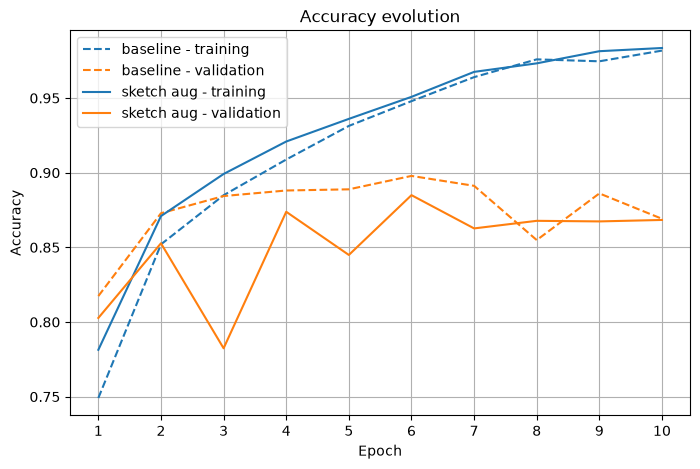

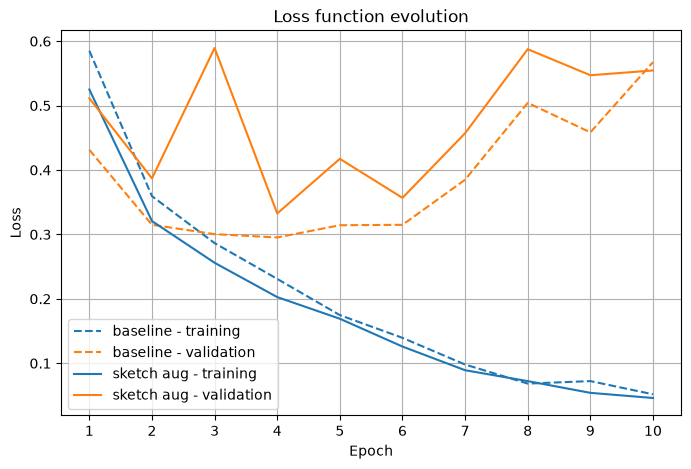

final training loss: 0.04603056237101555
final validation loss: 0.5545169115066528
--- generalization gap: 0.5084863491356373 ---

final training accuracy: 0.9835197329521179
final validation accuracy: 0.868359386920929
--- accuracy gap: 0.11516034603118896 ---


In [25]:
actual_epochs = range(1, epochs + 1)

for metric, title in [("accuracy", "Accuracy evolution"), ("loss", "Loss function evolution")]:
    plt.figure(figsize=(8, 5))
    plt.plot(actual_epochs, history_baseline.history[metric], "--", color="tab:blue", label="baseline - training")
    plt.plot(actual_epochs, history_baseline.history[f"val_{metric}"], "--", color="tab:orange", label="baseline - validation")
    plt.plot(actual_epochs, history_sketch_aug.history[metric], color="tab:blue", label="sketch aug - training")
    plt.plot(actual_epochs, history_sketch_aug.history[f"val_{metric}"], color="tab:orange", label="sketch aug - validation")
    plt.title(title)
    plt.xticks(actual_epochs)
    plt.xlabel("Epoch")
    plt.ylabel(metric.capitalize())
    plt.legend()
    plt.grid(True)
    plt.show()

aug_loss, aug_val_loss = history_sketch_aug.history["loss"], history_sketch_aug.history["val_loss"]
aug_acc, aug_val_acc = history_sketch_aug.history["accuracy"], history_sketch_aug.history["val_accuracy"]
print(f'final training loss: {aug_loss[-1]}\nfinal validation loss: {aug_val_loss[-1]}')
print(f'--- generalization gap: {abs(aug_loss[-1] - aug_val_loss[-1])} ---')
print(f'\nfinal training accuracy: {aug_acc[-1]}\nfinal validation accuracy: {aug_val_acc[-1]}')
print(f'--- accuracy gap: {abs(aug_acc[-1] - aug_val_acc[-1])} ---')

classe       precision    recall        f1   support
Painting         0.726     0.866     0.790      1206
Photo            0.863     0.716     0.783      1197
Schematics       0.944     0.893     0.918      1258
Sketch           0.834     0.985     0.903       199
Text             0.996     0.998     0.997      1248

accuracy globale : 0.8745


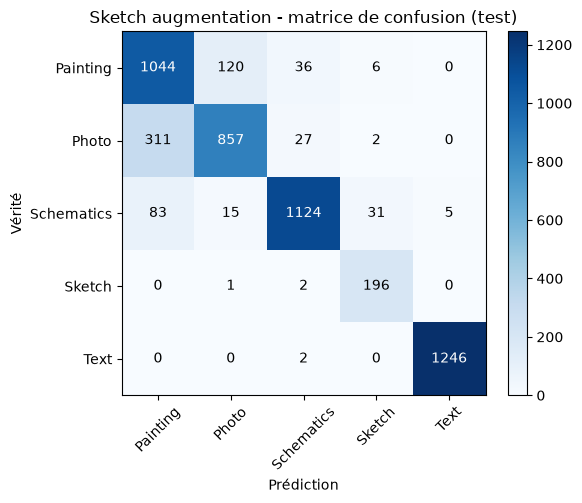

In [26]:
confusion_sketch_aug = per_class_metrics(model_sketch_aug, test_data)
plot_confusion(confusion_sketch_aug, "Sketch augmentation - matrice de confusion (test)")

Pour juger l'effet de l'augmentation, on compare surtout le **recall** et le **F1 de la classe `Sketch`** entre le baseline et ce modèle, ainsi que l'accuracy des autres classes (l'augmentation ne doit pas les dégrader). L'écart entre les courbes d'entraînement et de validation indique si le surapprentissage a diminué.